# Machine Learning #09 — Transformer Models in PyTorch 🤖

Today we meet the architecture behind **almost every modern language model**: the
**Transformer**. We will not build one from scratch — instead we will take a
**pre-trained** model, look inside it, and **fine-tune** it for our own task.

Everything runs in [PyTorch](https://pytorch.org/) together with the
🤗 [Hugging Face](https://huggingface.co/) libraries.

### Our workflow today

> **text → tokens → pre-trained model → embeddings & attention → fine-tuning → predictions**

##### ⚠️ Remember to set the **GPU** runtime in Colab! (`Runtime → Change runtime type → T4 GPU`)

# 📒 What is a Transformer?

The core idea is the **self-attention** mechanism: when the model processes a word,
it can **look at every other word in the sentence at the same time** and decide
which ones matter.

Take the sentence:

> *The animal didn't cross the street because **it** was too tired.*

To represent the word **it**, the model must know it refers to *the animal*, not to
*the street*. Self-attention lets the model build exactly this kind of link — and it
learns which links matter purely from data.

## ⚙️ Self-attention in one formula

Every token is projected into three vectors — a **query** $Q$, a **key** $K$ and a
**value** $V$. The output for each token is a weighted average of all values:

$$\text{Attention}(Q, K, V) = \text{softmax}\!\left(\frac{Q K^{\top}}{\sqrt{d_k}}\right) V$$

- $Q K^{\top}$ — how well does token *i* (query) match token *j* (key)? → a score
  for **every pair** of tokens
- $\sqrt{d_k}$ — a scaling factor that keeps the numbers in a healthy range
- $\text{softmax}$ — turns the scores into **weights that sum to 1** (this is the
  matrix we will plot later! 👀)
- multiplying by $V$ — each token becomes a **mix of the tokens it pays attention to**

A transformer does this many times in parallel with different projections
(**multi-head attention**), so different heads can specialise in different kinds of
relationships (grammar, coreference, ...).

## 🔎 How is this different from an RNN?

| | RNN / LSTM | Transformer |
|---|---|---|
| Reading the sequence | **one word at a time**, left to right | **whole sequence at once** |
| Memory of the past | a hidden state passed along | **direct access to every token** |
| Long dependencies | tend to fade away | one attention step away |
| Training | inherently **sequential** | **parallel** → GPU friendly |
| Word order | implicit in the order of processing | added explicitly (**positional embeddings**) |

Because everything is processed at once, the model has no idea about word order —
so the position of each token is **added into the input as a vector**.

## 🏗️ Two families of transformers

| Family | Direction | Good at | Examples |
|---|---|---|---|
| **Encoder** | sees the whole sentence (both directions) | *understanding* — classification, NER, search | BERT, DistilBERT, RoBERTa |
| **Decoder** | left to right only | *generating* text | GPT, Llama, Claude |

Today we use an **encoder** model, because our task is classification.

## 🎓 The pre-training → fine-tuning recipe

This is the reason transformers took over NLP:

1. **Pre-training** (done for us, on a huge corpus, costing thousands of GPU hours):
   the model learns general language by predicting masked words.
2. **Fine-tuning** (what we do today, in a couple of minutes):
   we attach a small **classification head** on top and train on our own,
   much smaller, labelled dataset.

> 💡 We are not learning English from scratch — we are teaching a model that
> already knows English how to solve *our* task.

## 🐣 Our model: DistilBERT

We will use [`distilbert-base-uncased`](https://huggingface.co/distilbert/distilbert-base-uncased):

- a **distilled** (compressed) version of BERT — it was trained to mimic BERT's outputs,
- **40 % smaller and 60 % faster**, while keeping ~97 % of BERT's performance,
- **6 transformer layers**, **12 attention heads**, hidden size **768**, ~**66 M parameters**,
- *uncased* = it lowercases everything, `English` and `english` are the same token.

For comparison: our little network in Lesson #01 had about **100 parameters**. 🦥

## ⚙️ Imports and setup

We need two Hugging Face libraries:

- **`transformers`** — the models and tokenizers themselves,
- **`datasets`** — a convenient loader for benchmark datasets.

Everything else (`torch`, `sklearn`, `matplotlib`) you already know.

In [ ]:
!pip install -q transformers datasets

In [ ]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import DataLoader

from datasets import load_dataset

from transformers import (
    pipeline,
    AutoTokenizer,
    AutoModel,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    get_linear_schedule_with_warmup,
)

from sklearn.metrics import (
    accuracy_score, confusion_matrix, classification_report, matthews_corrcoef
)
from sklearn.metrics.pairwise import cosine_similarity

sns.set_theme(style="whitegrid")

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch version:", torch.__version__)
print("device       :", device)

c:\Users\recka\Desktop\alex\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


torch version: 2.6.0+cu124
device       : cuda


In [2]:
# The pre-trained checkpoint we will use through the whole notebook.
# A "checkpoint" is simply a name of a model stored on the Hugging Face Hub.
CHECKPOINT = "distilbert-base-uncased"

# 🚀 Part 1 — A transformer in three lines

Before we dissect anything, let's see what these models can do out of the box.

The **`pipeline`** helper wraps the *whole* chain — tokenizer → model → post-processing —
into a single callable object. Here we use a DistilBERT that someone has **already
fine-tuned** for sentiment analysis.

> 💡 The first run downloads the model (~250 MB), so it takes a few seconds.

In [3]:
# task name  +  model checkpoint  ->  ready-to-use predictor
sentiment = pipeline(
    "sentiment-analysis",
    model="distilbert-base-uncased-finetuned-sst-2-english",
    device=0 if torch.cuda.is_available() else -1,   # 0 = first GPU, -1 = CPU
)

c:\Users\recka\Desktop\alex\.venv\lib\site-packages\huggingface_hub\file_download.py:141: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\recka\.cache\huggingface\hub\models--distilbert-base-uncased-finetuned-sst-2-english. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Loading weights: 100%|██████████| 104/104 [00:00<00:00, 17335.97it/s]


In [4]:
sentiment("I absolutely loved this movie, the acting was brilliant!")

[{'label': 'POSITIVE', 'score': 0.9998812675476074}]

In [5]:
# The pipeline also accepts a list of texts and returns one dict per text
reviews = [
    "The plot was predictable and the characters were flat.",
    "A masterpiece. I would watch it again tomorrow.",
    "It was okay, nothing special.",
]

for text, result in zip(reviews, sentiment(reviews)):
    print(f"{result['label']:>8}  ({result['score']:.3f})  |  {text}")

NEGATIVE  (1.000)  |  The plot was predictable and the characters were flat.
POSITIVE  (1.000)  |  A masterpiece. I would watch it again tomorrow.
NEGATIVE  (0.982)  |  It was okay, nothing special.


### 🤔 What just happened?

Three lines gave us a model with **66 million parameters** that reaches ~91 % accuracy
on movie-review sentiment. Notice that we never wrote a single layer, loss function
or training loop.

That convenience hides a lot, though — and hidden machinery is hard to debug and
impossible to adapt. So for the rest of the notebook we **open the box**.

## ✏️ Activity 1 — Break the model 💥

Sentiment models are famously bad at **sarcasm**, **negation** and **mixed opinions**.

**Your task:** find at least **two** sentences where the model is confidently *wrong*,
and one where it is *unsure* (score close to 0.5).

In [ ]:
my_sentences = [
]

for text, result in zip(my_sentences, sentiment(my_sentences)):
    print(f"{result['label']:>8}  ({result['score']:.3f})  |  {text}")

# 🔤 Part 2 — The tokenizer

A neural network cannot read text — it needs **numbers**. The **tokenizer** does that
conversion, and it is *part of the model*: every checkpoint ships with the exact
tokenizer it was trained with.

`AutoTokenizer.from_pretrained` downloads the right one automatically.

In [9]:
tokenizer = AutoTokenizer.from_pretrained(CHECKPOINT)
tokenizer

c:\Users\recka\Desktop\alex\.venv\lib\site-packages\huggingface_hub\file_download.py:141: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\recka\.cache\huggingface\hub\models--distilbert-base-uncased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


BertTokenizer(name_or_path='distilbert-base-uncased', vocab_size=30522, model_max_length=512, padding_side='right', truncation_side='right', special_tokens={'unk_token': '[UNK]', 'sep_token': '[SEP]', 'pad_token': '[PAD]', 'cls_token': '[CLS]', 'mask_token': '[MASK]'}, added_tokens_decoder={
	0: AddedToken("[PAD]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	100: AddedToken("[UNK]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	101: AddedToken("[CLS]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	102: AddedToken("[SEP]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	103: AddedToken("[MASK]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
})

In [10]:
text = "Transformers are changing machine learning."

encoded = tokenizer(text)
encoded

{'input_ids': [101, 19081, 2024, 5278, 3698, 4083, 1012, 102], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1]}

### What is inside the output?

| Key | Meaning |
|---|---|
| `input_ids` | the **id of every token** in the model's vocabulary |
| `attention_mask` | `1` = a real token, `0` = padding that must be **ignored** |

Let's translate the ids back into readable tokens.

In [11]:
tokens = tokenizer.convert_ids_to_tokens(encoded["input_ids"])
tokens

['[CLS]',
 'transformers',
 'are',
 'changing',
 'machine',
 'learning',
 '.',
 '[SEP]']

### 🎁 Special tokens

Two tokens were added that we never wrote:

- **`[CLS]`** — *classification* token, always the first one. Its final vector is used
  as a **summary of the whole sentence** (we will use it soon!).
- **`[SEP]`** — *separator*, marks the end of a sentence (or the boundary between two
  sentences, e.g. for question–answer pairs).

In [12]:
print("Vocabulary size :", tokenizer.vocab_size)
print("Special tokens  :", tokenizer.all_special_tokens)
print("[CLS] id        :", tokenizer.cls_token_id)
print("[SEP] id        :", tokenizer.sep_token_id)
print("[PAD] id        :", tokenizer.pad_token_id)

Vocabulary size : 30522
Special tokens  : ['[UNK]', '[SEP]', '[PAD]', '[CLS]', '[MASK]']
[CLS] id        : 101
[SEP] id        : 102
[PAD] id        : 0


### 🧩 Subword tokenization

The vocabulary has only ~30 000 entries, but English has far more words — and users
invent new ones all the time. The trick: **rare words are split into pieces**
(*subwords*). The prefix `##` means *"this piece continues the previous token"*.

This way the model can represent **any** word, even one it has never seen.

In [13]:
weird = "Tokenization of unbelievably hyperparametrized transformers is unquestionable."

print(tokenizer.tokenize(weird))

['token', '##ization', 'of', 'un', '##bel', '##ie', '##va', '##bly', 'hyper', '##para', '##met', '##rized', 'transformers', 'is', 'un', '##quest', '##ion', '##able', '.']


In [14]:
# Number of words vs. number of tokens
print("words :", len(weird.split()))
print("tokens:", len(tokenizer.tokenize(weird)))

words : 7
tokens: 19


> 💡 This is why model limits are given in **tokens**, not words. A rough rule of
> thumb for English: **1 word ≈ 1.3 tokens**. For Czech (with a model trained mostly
> on English) it is much worse — try it in the cell below!

In [15]:
czech = "Transformátorové modely změnily strojové učení."
print(tokenizer.tokenize(czech))
print("words :", len(czech.split()), "| tokens:", len(tokenizer.tokenize(czech)))

['transform', '##ator', '##ove', 'model', '##y', 'z', '##men', '##ily', 'st', '##ro', '##jo', '##ve', 'uc', '##eni', '.']
words : 5 | tokens: 15


### 📦 Batches: padding and truncation

Sentences have different lengths, but a tensor must be **rectangular**. So we:

- **pad** shorter sentences with `[PAD]` up to the longest one in the batch,
- **truncate** anything longer than the model's limit (BERT/DistilBERT: **512 tokens**).

The `attention_mask` then tells the model *"ignore these padded positions"*.

In [16]:
batch_texts = [
    "Short one.",
    "This sentence is considerably longer than the previous one.",
]

batch = tokenizer(
    batch_texts,
    padding=True,            # pad to the longest sequence in the batch
    truncation=True,         # cut anything above max_length
    max_length=32,
    return_tensors="pt",     # "pt" = PyTorch tensors (this is the PyTorch world 🔥)
)

batch

{'input_ids': tensor([[ 101, 2460, 2028, 1012,  102,    0,    0,    0,    0,    0,    0,    0],
        [ 101, 2023, 6251, 2003, 9839, 2936, 2084, 1996, 3025, 2028, 1012,  102]]), 'token_type_ids': tensor([[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]]), 'attention_mask': tensor([[1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]])}

In [17]:
# Both sequences now have exactly the same shape
batch["input_ids"].shape

torch.Size([2, 12])

In [18]:
# Look at the padded sentence: [PAD] tokens have attention_mask = 0
for tok, mask in zip(tokenizer.convert_ids_to_tokens(batch["input_ids"][0]),
                     batch["attention_mask"][0].tolist()):
    print(f"{tok:>12}  ->  mask = {mask}")

       [CLS]  ->  mask = 1
       short  ->  mask = 1
         one  ->  mask = 1
           .  ->  mask = 1
       [SEP]  ->  mask = 1
       [PAD]  ->  mask = 0
       [PAD]  ->  mask = 0
       [PAD]  ->  mask = 0
       [PAD]  ->  mask = 0
       [PAD]  ->  mask = 0
       [PAD]  ->  mask = 0
       [PAD]  ->  mask = 0


In [19]:
# And back from ids to text
tokenizer.decode(batch["input_ids"][0], skip_special_tokens=True)

'short one.'

# 🧠 Part 3 — Inside the model

There are two ways to load a transformer:

| Class | What you get | Use it for |
|---|---|---|
| `AutoModel` | the **backbone** only — a vector for every token | embeddings, feature extraction, exploration |
| `AutoModelForSequenceClassification` | backbone **+ a small classification head** | classification, fine-tuning |

Let's start with the bare backbone to see what a transformer actually outputs.

In [20]:
backbone = AutoModel.from_pretrained(CHECKPOINT).to(device)
backbone.eval()          # evaluation mode: no dropout (we are not training yet)
print(backbone.config)

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 19998.59it/s]
[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


DistilBertConfig {
  "activation": "gelu",
  "architectures": [
    "DistilBertForMaskedLM"
  ],
  "attention_dropout": 0.1,
  "bos_token_id": null,
  "dim": 768,
  "dropout": 0.1,
  "dtype": "float32",
  "eos_token_id": null,
  "hidden_dim": 3072,
  "initializer_range": 0.02,
  "max_position_embeddings": 512,
  "model_type": "distilbert",
  "n_heads": 12,
  "n_layers": 6,
  "pad_token_id": 0,
  "qa_dropout": 0.1,
  "seq_classif_dropout": 0.2,
  "sinusoidal_pos_embds": false,
  "tie_weights_": true,
  "tie_word_embeddings": true,
  "transformers_version": "5.16.1",
  "vocab_size": 30522
}



In [21]:
n_params = sum(p.numel() for p in backbone.parameters())
print(f"Number of parameters: {n_params:,}")

Number of parameters: 66,362,880


In [22]:
# The architecture: embeddings + 6 transformer blocks
backbone

DistilBertModel(
  (embeddings): Embeddings(
    (word_embeddings): Embedding(30522, 768, padding_idx=0)
    (position_embeddings): Embedding(512, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (transformer): Transformer(
    (layer): ModuleList(
      (0-5): 6 x TransformerBlock(
        (attention): DistilBertSelfAttention(
          (q_lin): Linear(in_features=768, out_features=768, bias=True)
          (k_lin): Linear(in_features=768, out_features=768, bias=True)
          (v_lin): Linear(in_features=768, out_features=768, bias=True)
          (out_lin): Linear(in_features=768, out_features=768, bias=True)
          (dropout): Dropout(p=0.1, inplace=False)
        )
        (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
        (ffn): FFN(
          (dropout): Dropout(p=0.1, inplace=False)
          (lin1): Linear(in_features=768, out_features=3072, bias=True)
          (lin2): L

## 📐 What comes out of a transformer?

We push a sentence through the model. We use
**`torch.no_grad()`** — we are only doing inference, so no gradients are needed
(it is faster and saves memory).

In [23]:
sentence = "The cat sat on the mat."

inputs = tokenizer(sentence, return_tensors="pt").to(device)   # don't forget .to(device)!

with torch.no_grad():
    outputs = backbone(**inputs)     # ** unpacks input_ids and attention_mask as arguments

outputs.last_hidden_state.shape

torch.Size([1, 9, 768])

### Reading the shape: `(batch_size, sequence_length, hidden_size)`

- **1** — one sentence in the batch
- **9** — number of tokens (`[CLS]` + 7 tokens + `[SEP]`)
- **768** — the size of the vector representing **each token**

So the model does *not* return one vector per sentence — it returns
**one 768-dimensional vector per token**. 🎯

In [24]:
print("tokens:", tokenizer.convert_ids_to_tokens(inputs["input_ids"][0]))
print("shape :", outputs.last_hidden_state.shape)

# The vector of the very first token ([CLS]) - just the first 10 numbers
outputs.last_hidden_state[0, 0, :10]

tokens: ['[CLS]', 'the', 'cat', 'sat', 'on', 'the', 'mat', '.', '[SEP]']
shape : torch.Size([1, 9, 768])


tensor([-0.2713, -0.0781, -0.0216,  0.0169, -0.0531, -0.1490, -0.1098,  0.4255,
        -0.2861, -0.2226], device='cuda:0')

## ✨ Contextual embeddings — the key idea

In classic embeddings (word2vec, GloVe) every word has **one fixed vector**.
The word *bank* is the same vector in *river bank* and in *investment bank*.

A transformer builds the vector **from the context** — so the same word gets
**different vectors in different sentences**. Let's prove it.

In [25]:
# Return the contextual vector of a given word inside a given sentence
def token_embedding(sentence, word):
    enc = tokenizer(sentence, return_tensors="pt").to(device)
    with torch.no_grad():
        hidden = backbone(**enc).last_hidden_state          # (1, seq_len, 768)

    tokens = tokenizer.convert_ids_to_tokens(enc["input_ids"][0])
    idx = tokens.index(word)                                # position of our word
    return hidden[0, idx].cpu().numpy()

In [26]:
sent_a = "I deposited the money at the bank yesterday."     # financial
sent_b = "The savings bank raised its interest rates."      # financial
sent_c = "We sat on the river bank and watched the sunset." # geographical

vectors = np.stack([
    token_embedding(sent_a, "bank"),
    token_embedding(sent_b, "bank"),
    token_embedding(sent_c, "bank"),
])

vectors.shape

(3, 768)

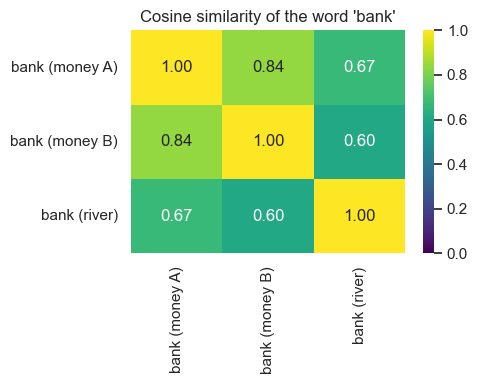

In [27]:
labels = ["bank (money A)", "bank (money B)", "bank (river)"]
sim = cosine_similarity(vectors)

plt.figure(figsize=(5, 4))
sns.heatmap(sim, annot=True, fmt=".2f", cmap="viridis",
            xticklabels=labels, yticklabels=labels, vmin=0, vmax=1)
plt.title("Cosine similarity of the word 'bank'")
plt.tight_layout()
plt.show()

> 💡 The two *financial* banks are much closer to each other than to the *river* bank —
> although the input word was **identical**. The model disambiguated the meaning purely
> from the surrounding words. This is what "contextual" means.

## 🧵 From tokens to one sentence vector

Often we want a **single vector per sentence**. Two standard options:

1. **`[CLS]` pooling** — take the vector of the first token (it is trained to summarise).
2. **Mean pooling** — average all *real* tokens (padding must be excluded via the mask).

Mean pooling usually works better for similarity tasks, so we use it here.

In [28]:
def mean_pool(last_hidden_state, attention_mask):
    # attention_mask: (batch, seq) -> (batch, seq, 1) so it broadcasts over the 768 dims
    mask = attention_mask.unsqueeze(-1).float()
    summed = (last_hidden_state * mask).sum(dim=1)   # sum only real tokens
    counts = mask.sum(dim=1)                         # how many real tokens
    return summed / counts


def sentence_embeddings(sentences):
    enc = tokenizer(sentences, padding=True, truncation=True, return_tensors="pt").to(device)
    with torch.no_grad():
        hidden = backbone(**enc).last_hidden_state
    return mean_pool(hidden, enc["attention_mask"]).cpu().numpy()

In [29]:
sentences = [
    "The weather is beautiful today.",
    "It is a lovely sunny day.",
    "My laptop crashed again during the exam.",
    "The computer keeps freezing when I work.",
    "She adopted a small orange kitten.",
]

emb = sentence_embeddings(sentences)
print("embeddings shape:", emb.shape)      # (5 sentences, 768)

embeddings shape: (5, 768)


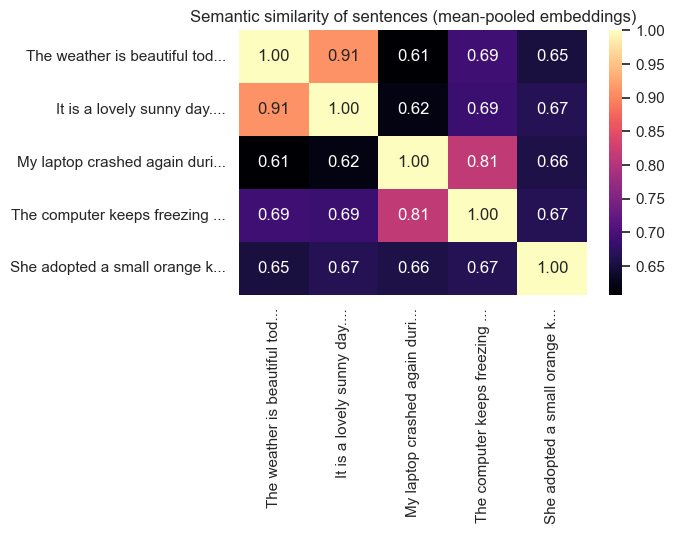

In [30]:
sim = cosine_similarity(emb)
short = [s[:28] + "..." for s in sentences]

plt.figure(figsize=(7, 5.5))
sns.heatmap(sim, annot=True, fmt=".2f", cmap="magma",
            xticklabels=short, yticklabels=short)
plt.title("Semantic similarity of sentences (mean-pooled embeddings)")
plt.tight_layout()
plt.show()

> 🔎 Sentences 1–2 (weather) and 3–4 (broken computer) form clear pairs, even though
> they **share almost no words**. This is the basis of semantic search, clustering and
> recommendation systems — and we got it *without any training*.

# 👀 Part 4 — Looking inside attention

So far attention was an abstract formula. Now we plot it.

Every model can return its attention weights if we ask with
**`output_attentions=True`**. What we get back is the
$\text{softmax}\!\left(\frac{QK^{\top}}{\sqrt{d_k}}\right)$ matrix — for **every layer**
and **every head**.

## ⚠️ One catch: fast attention hides the matrix

Modern versions of 🤗 `transformers` use **SDPA** (*scaled dot-product attention*) by
default — a fused PyTorch kernel that is faster and uses far less memory. It achieves
that by **never building the full `seq × seq` matrix**: the softmax and the
multiplication by $V$ happen block by block directly in GPU memory.

Great for speed, useless for us — there is simply nothing to return, so
`output_attentions=True` is ignored and we get an empty tuple.

To inspect attention we must ask for the **`eager`** implementation, i.e. the plain
textbook version that really materialises the matrix.

| Implementation | Speed | Returns attention weights? |
|---|---|---|
| `sdpa` (default) | ⚡ fast | ❌ no |
| `eager` | 🐢 slower | ✅ yes |

In [32]:
# Load the same checkpoint again, but with the "eager" attention implementation
# so that the attention matrices are actually computed and returned.
# The weights are already cached, so this is instant.
backbone_eager = AutoModel.from_pretrained(
    CHECKPOINT,
    attn_implementation="eager",     # <- the important part
).to(device)

backbone_eager.eval()

print("attention implementation:", backbone_eager.config._attn_implementation)

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 19990.01it/s]
[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


attention implementation: eager


### Reading the shape: `(batch, heads, seq_len, seq_len)`

- **6 layers** × **12 heads** = **72 attention matrices** for a single sentence!
- each matrix is `seq_len × seq_len`: row *i* tells us **how much token *i* attends to
  every other token**
- every **row sums to 1** (that is what softmax guarantees)

In [33]:
# Helper: run a sentence through the model and return its attention maps + tokens
def get_attention(sentence):
    enc = tokenizer(sentence, return_tensors="pt").to(device)

    with torch.no_grad():
        out = backbone_eager(**enc, output_attentions=True)

    tokens = tokenizer.convert_ids_to_tokens(enc["input_ids"][0])
    return out.attentions, tokens


# Plot the attention matrix of one head in one layer.
# attentions + tokens come from get_attention(); head=None averages all 12 heads.
def plot_attention(attentions, tokens, layer, head=0, title=None):
    if head is None:
        matrix = attentions[layer][0].mean(dim=0).cpu().numpy()   # average over heads
        head_name = "mean of all heads"
    else:
        matrix = attentions[layer][0, head].cpu().numpy()          # (seq_len, seq_len)
        head_name = f"head {head}"

    plt.figure(figsize=(8, 6.5))
    sns.heatmap(matrix, xticklabels=tokens, yticklabels=tokens,
                cmap="Blues", vmin=0, square=True, cbar_kws={"shrink": 0.7})
    plt.title(title or f"Attention — layer {layer}, {head_name}")
    plt.ylabel("query token (who is looking)")
    plt.xlabel("key token (where it looks)")
    plt.tight_layout()
    plt.show()


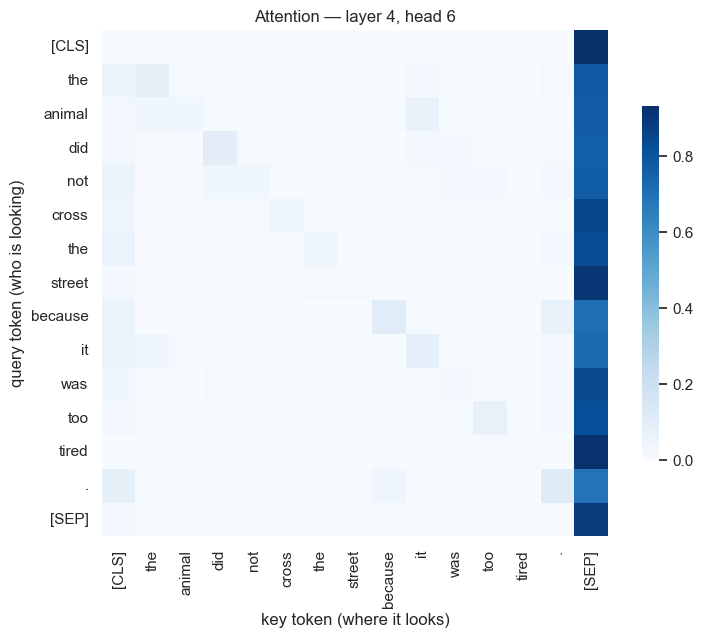

In [35]:
att_sentence = "The animal did not cross the street because it was too tired."
att, tokens = get_attention(att_sentence)
plot_attention(att, tokens, layer=4, head=6)

In [ ]:
# Plot all 12 heads of one layer at once - the fastest way to spot patterns
def plot_all_heads(attentions, tokens, layer):
    fig, axes = plt.subplots(3, 4, figsize=(16, 12))

    for head, ax in enumerate(axes.flat):
        sns.heatmap(attentions[layer][0, head].cpu().numpy(), ax=ax,
                    cmap="Blues", vmin=0, cbar=False, square=True,
                    xticklabels=tokens if head >= 8 else False,
                    yticklabels=tokens if head % 4 == 0 else False)
        ax.set_title(f"head {head}", fontsize=10)
        ax.tick_params(labelsize=7)

    fig.suptitle(f"All 12 attention heads — layer {layer}", fontsize=15)
    plt.tight_layout()
    plt.show()


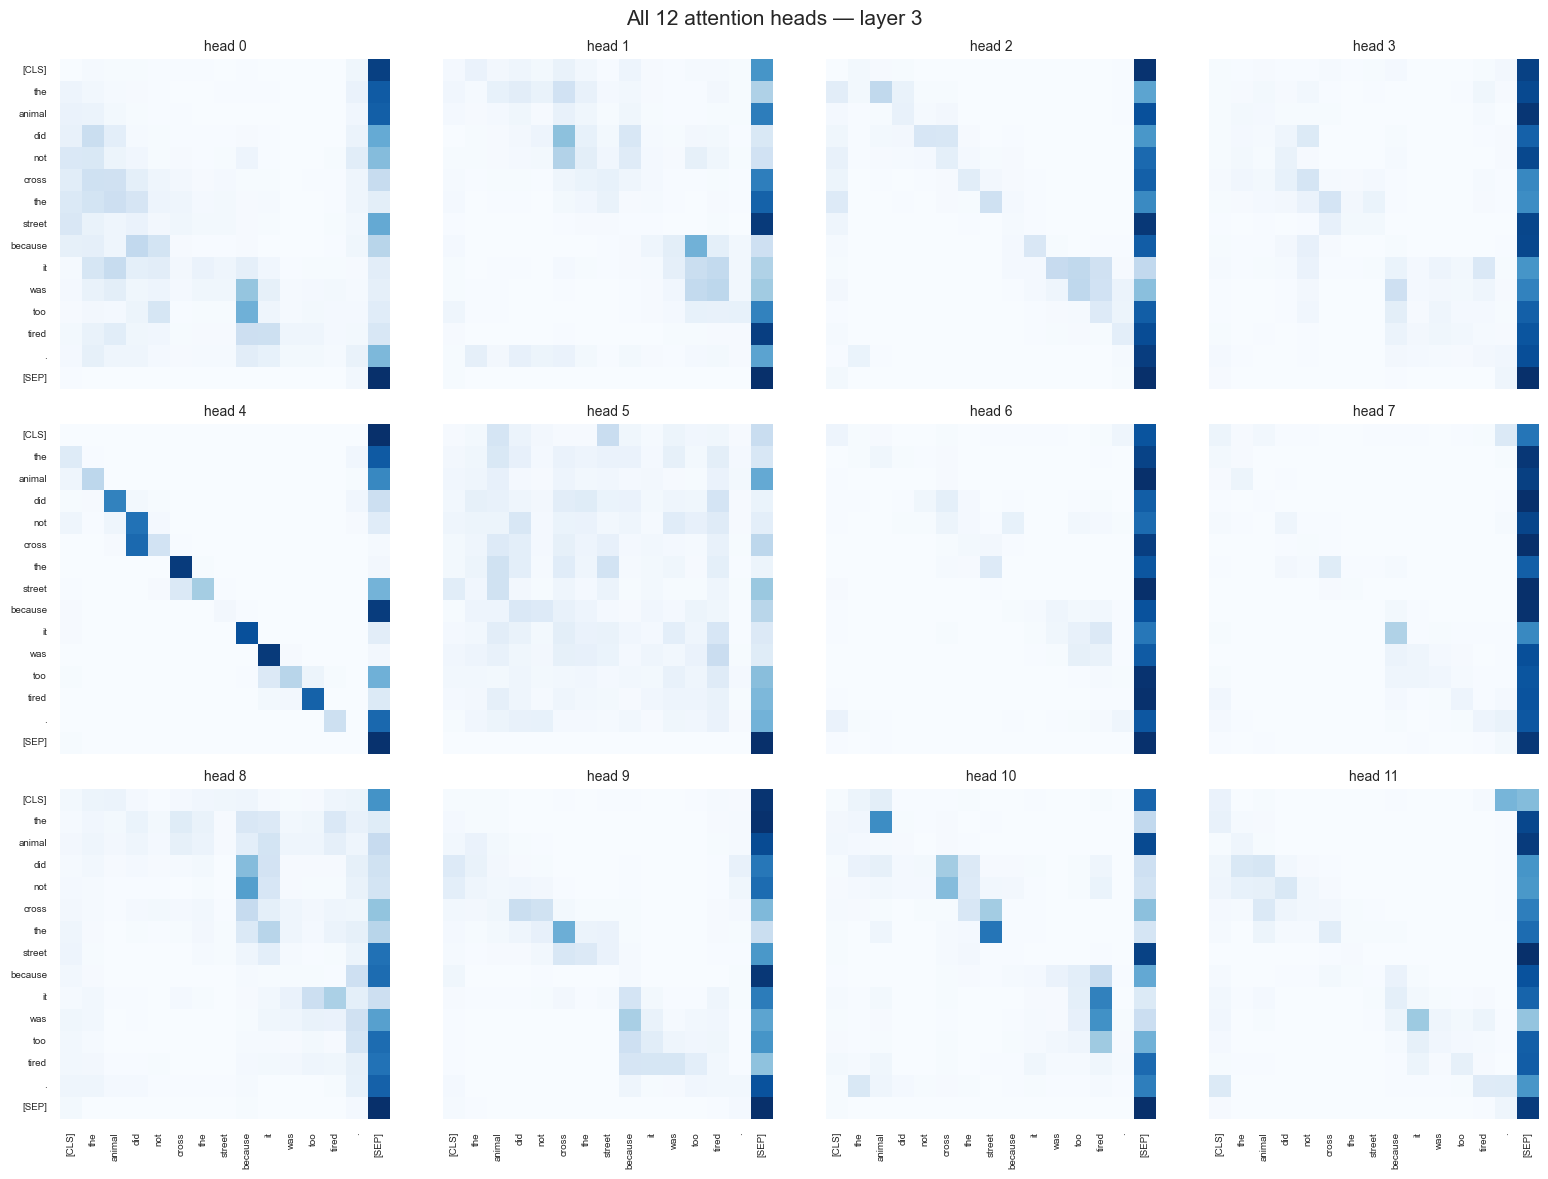

In [39]:
plot_all_heads(att, tokens, layer=3)

# 🎯 Part 5 — Fine-tuning #1: sentiment (SST-2)

Time to **train**. We take the pre-trained DistilBERT, attach a fresh classification
head, and teach it a task from the [GLUE benchmark](https://gluebenchmark.com/) —
a standard collection of nine English language-understanding datasets.

### Our task: SST-2 (Stanford Sentiment Treebank)

- **Input:** one sentence (a fragment of a movie review)
- **Output:** `0` = negative, `1` = positive
- **Metric:** accuracy

| GLUE task | What it decides |
|---|---|
| **`sst2`** | sentiment of a sentence ← *we start here* |
| **`cola`** | is the sentence grammatically acceptable? ← *we do this one too* |
| `mrpc` | are two sentences paraphrases? |
| `qnli` | does a sentence answer a question? |
| `rte`, `mnli` | does one sentence entail another? |
| `stsb` | how similar are two sentences (regression) |
| `qqp` | are two Quora questions duplicates? |

In [41]:
raw_sst2 = load_dataset("nyu-mll/glue", "sst2")
raw_sst2

c:\Users\recka\Desktop\alex\.venv\lib\site-packages\huggingface_hub\file_download.py:141: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\recka\.cache\huggingface\hub\datasets--nyu-mll--glue. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Generating test split: 100%|██████████| 1821/1821 [00:00<00:00, 909373.45 examples/s]


DatasetDict({
    train: Dataset({
        features: ['sentence', 'label', 'idx'],
        num_rows: 67349
    })
    validation: Dataset({
        features: ['sentence', 'label', 'idx'],
        num_rows: 872
    })
    test: Dataset({
        features: ['sentence', 'label', 'idx'],
        num_rows: 1821
    })
})

In [42]:
# One example: the text, the label and an index
raw_sst2["train"][0]

{'sentence': 'hide new secretions from the parental units ',
 'label': 0,
 'idx': 0}

In [43]:
# What do the label numbers mean?
raw_sst2["train"].features["label"]

ClassLabel(names=['negative', 'positive'])

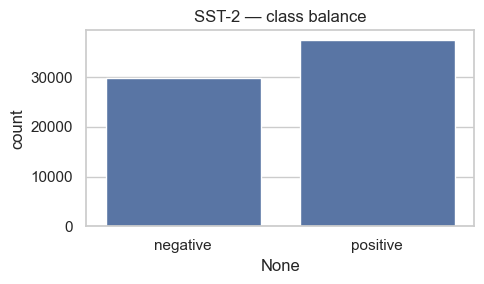

positive    0.558
negative    0.442
Name: proportion, dtype: float64


In [44]:
# Class balance - are the two classes roughly equally represented?
sst2_labels = pd.Series(raw_sst2["train"]["label"]).map({0: "negative", 1: "positive"})

plt.figure(figsize=(5, 3))
sns.countplot(x=sst2_labels)
plt.title("SST-2 — class balance")
plt.tight_layout()
plt.show()

print(sst2_labels.value_counts(normalize=True).round(3))

### 🐢 Keeping the lab fast

The full SST-2 training set has ~67 000 sentences. Fine-tuning on all of them takes
tens of minutes, and we would learn nothing new from it. We take a **random subset**
instead — the model is already pre-trained, so a few thousand examples get us
surprisingly far.

In [45]:
N_TRAIN = 4000          # try changing this later (Activity 5)
MAX_LEN = 64            # SST-2 sentences are short, 64 tokens is plenty
BATCH_SIZE = 32

sst2_train_raw = raw_sst2["train"].shuffle(seed=SEED).select(range(N_TRAIN))
sst2_eval_raw  = raw_sst2["validation"]

len(sst2_train_raw), len(sst2_eval_raw)

(4000, 872)

## 🧹 Preprocessing: tokenize the whole dataset

`dataset.map()` applies our tokenizing function to **every example** (in batches, so it
is fast). Then we keep only the columns the model expects.

> ⚠️ The label column **must be named `labels`** — the model looks for exactly this name.

In [46]:
def encode(dataset, text_key, max_length=MAX_LEN):
    # 1) tokenize (no padding here - the collator will pad each batch separately)
    def tok(batch):
        return tokenizer(batch[text_key], truncation=True, max_length=max_length)

    encoded = dataset.map(tok, batched=True)

    # 2) drop everything the model does not need (raw text, idx, ...)
    keep = {"input_ids", "attention_mask", "label"}
    encoded = encoded.remove_columns([c for c in encoded.column_names if c not in keep])

    # 3) rename label -> labels and return PyTorch tensors
    encoded = encoded.rename_column("label", "labels")
    encoded.set_format("torch")
    return encoded

In [47]:
sst2_train = encode(sst2_train_raw, "sentence")
sst2_eval  = encode(sst2_eval_raw,  "sentence")

sst2_train

Map: 100%|██████████| 872/872 [00:00<00:00, 21800.41 examples/s]


Dataset({
    features: ['labels', 'input_ids', 'attention_mask'],
    num_rows: 4000
})

In [48]:
sst2_train[0]

{'labels': tensor(1),
 'input_ids': tensor([  101, 12555,  1010, 11951,  1999, 22092,  2066,  2137, 11345,  1998,
          2757,  1011,  2006,  1999,  2602,  1010,   102]),
 'attention_mask': tensor([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1])}

### 🚚 DataLoader + dynamic padding

We use a **`DataLoader`**, which serves the data in
**mini-batches**.

`DataCollatorWithPadding` pads each batch to the length of *its own* longest sequence
(**dynamic padding**). Padding everything to 512 tokens would waste a lot of compute.

In [49]:
collator = DataCollatorWithPadding(tokenizer=tokenizer)

sst2_train_loader = DataLoader(sst2_train, batch_size=BATCH_SIZE, shuffle=True,  collate_fn=collator)
sst2_eval_loader  = DataLoader(sst2_eval,  batch_size=BATCH_SIZE, shuffle=False, collate_fn=collator)

print("training batches:", len(sst2_train_loader))

training batches: 125


In [50]:
# Peek at one batch - notice the shapes
example_batch = next(iter(sst2_train_loader))
{k: v.shape for k, v in example_batch.items()}

{'labels': torch.Size([32]),
 'input_ids': torch.Size([32, 37]),
 'attention_mask': torch.Size([32, 37])}

## 🏗️ The model with a classification head

`AutoModelForSequenceClassification` = the pre-trained backbone **+ a small head**:

$$\text{[CLS] vector (768)} \;\rightarrow\; \text{Linear} \;\rightarrow\; \text{ReLU} \;\rightarrow\; \text{Linear} \;\rightarrow\; \text{2 logits}$$

The backbone weights come from pre-training, but the **head is brand new and random**.
Hugging Face warns you about exactly that — the message below is **expected, not an error**. 😉

In [51]:
id2label = {0: "negative", 1: "positive"}
label2id = {v: k for k, v in id2label.items()}

model_sst2 = AutoModelForSequenceClassification.from_pretrained(
    CHECKPOINT,
    num_labels=2,
    id2label=id2label,
    label2id=label2id,
).to(device)

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 16665.89it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [52]:
# The classification head sitting on top of the transformer
model_sst2.classifier, model_sst2.pre_classifier

(Linear(in_features=768, out_features=2, bias=True),
 Linear(in_features=768, out_features=768, bias=True))

## 🧪 Baseline: how good is the model *before* training?

Always measure this. The head is random, so we expect **~50 %** — pure coin flipping.

In [53]:
def predict(model, loader):
    model.eval()                       # evaluation mode
    logits_all, labels_all = [], []

    with torch.no_grad():              # no gradients -> faster, less memory
        for batch in loader:
            labels_all.append(batch["labels"].numpy())
            batch = {k: v.to(device) for k, v in batch.items()}
            logits_all.append(model(**batch).logits.cpu().numpy())

    return np.concatenate(logits_all), np.concatenate(labels_all)

In [54]:
logits, y_true = predict(model_sst2, sst2_eval_loader)
y_pred = logits.argmax(axis=1)         # highest logit wins

print(f"Accuracy BEFORE fine-tuning: {accuracy_score(y_true, y_pred):.3f}")

Accuracy BEFORE fine-tuning: 0.403


## ⭐ The training loop

In [55]:
from tqdm.auto import tqdm


def train_model(model, train_loader, val_loader, epochs=2, lr=2e-5):
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr)

    total_steps = epochs * len(train_loader)
    scheduler = get_linear_schedule_with_warmup(
        optimizer, num_warmup_steps=0, num_training_steps=total_steps
    )

    history = {"step_loss": [], "val_loss": []}

    for epoch in range(epochs):
        # ---------- training ----------
        model.train()                                   # training mode (dropout ON)
        for batch in tqdm(train_loader, desc=f"epoch {epoch + 1}/{epochs}"):
            batch = {k: v.to(device) for k, v in batch.items()}

            outputs = model(**batch)                    # 1) forward pass
            loss = outputs.loss                         # 2) loss (computed inside!)

            optimizer.zero_grad()                       #    reset gradients
            loss.backward()                             # 3) backward pass
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)   # stabilise
            optimizer.step()                            # 4) update the weights
            scheduler.step()                            #    decay the learning rate

            history["step_loss"].append(loss.item())

        # ---------- validation ----------
        model.eval()
        val_losses = []
        with torch.no_grad():
            for batch in val_loader:
                batch = {k: v.to(device) for k, v in batch.items()}
                val_losses.append(model(**batch).loss.item())

        val_loss = float(np.mean(val_losses))
        history["val_loss"].append(val_loss)
        print(f"  -> epoch {epoch + 1}: validation loss = {val_loss:.4f}")

    return history

In [56]:
%%time
history_sst2 = train_model(model_sst2, sst2_train_loader, sst2_eval_loader, epochs=2, lr=2e-5)

epoch 1/2: 100%|██████████| 125/125 [00:03<00:00, 41.09it/s]


  -> epoch 1: validation loss = 0.3431


epoch 2/2: 100%|██████████| 125/125 [00:02<00:00, 43.44it/s]


  -> epoch 2: validation loss = 0.3305
CPU times: total: 6.23 s
Wall time: 6.32 s


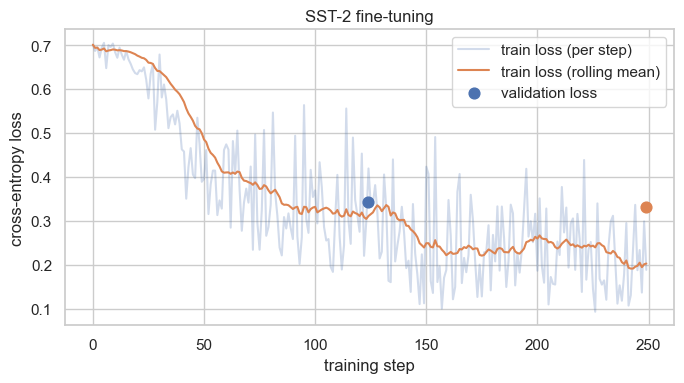

In [58]:
steps = np.arange(len(history_sst2["step_loss"]))
rolling = pd.Series(history_sst2["step_loss"]).rolling(20, min_periods=1).mean()

plt.figure(figsize=(7, 4))
plt.plot(steps, history_sst2["step_loss"], alpha=0.25, label="train loss (per step)")
plt.plot(steps, rolling, label="train loss (rolling mean)")

# validation loss is measured once per epoch -> draw it at the end of each epoch
steps_per_epoch = len(sst2_train_loader)
for i, vl in enumerate(history_sst2["val_loss"]):
    plt.scatter((i + 1) * steps_per_epoch - 1, vl, marker="o", s=60, zorder=5,
                label="validation loss" if i == 0 else None)

plt.xlabel("training step")
plt.ylabel("cross-entropy loss")
plt.title("SST-2 fine-tuning")
plt.legend()
plt.tight_layout()
plt.show()

## 📊 Evaluation

In [59]:
logits, y_true = predict(model_sst2, sst2_eval_loader)
y_pred = logits.argmax(axis=1)

print(f"Accuracy AFTER fine-tuning: {accuracy_score(y_true, y_pred):.3f}")
print()
print(classification_report(y_true, y_pred, target_names=["negative", "positive"]))

Accuracy AFTER fine-tuning: 0.856

              precision    recall  f1-score   support

    negative       0.85      0.85      0.85       428
    positive       0.86      0.86      0.86       444

    accuracy                           0.86       872
   macro avg       0.86      0.86      0.86       872
weighted avg       0.86      0.86      0.86       872



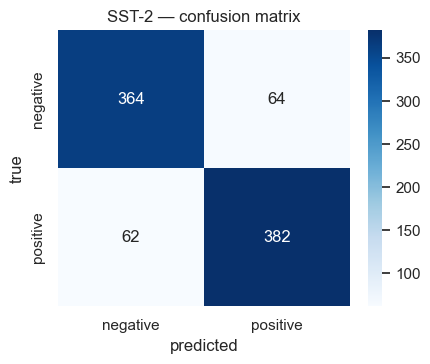

In [60]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(4.5, 3.8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["negative", "positive"], yticklabels=["negative", "positive"])
plt.xlabel("predicted"); plt.ylabel("true")
plt.title("SST-2 — confusion matrix")
plt.tight_layout(); plt.show()

## 🔮 Inference on our own sentences

The same recipe as before: tokenize → forward pass → `softmax` → `argmax`.
Here we apply softmax explicitly because we want the **probabilities**, not just the class.

In [61]:
def classify(model, sentences, max_length=MAX_LEN):
    enc = tokenizer(sentences, padding=True, truncation=True,
                    max_length=max_length, return_tensors="pt").to(device)

    model.eval()
    with torch.no_grad():
        logits = model(**enc).logits

    probs = torch.softmax(logits, dim=-1).cpu().numpy()   # logits -> probabilities
    preds = probs.argmax(axis=1)

    return pd.DataFrame({
        "sentence": sentences,
        "prediction": [model.config.id2label[p] for p in preds],
        "confidence": probs.max(axis=1).round(3),
    })

In [62]:
my_reviews = [
    "The soundtrack alone is worth the ticket.",
    "I have never been so bored in a cinema.",
    "A slow start, but the ending completely won me over.",
]

classify(model_sst2, my_reviews)

,sentence,prediction,confidence
0,The soundtrack alone is worth the ticket.,positive,0.924
1,I have never been so bored in a cinema.,positive,0.577
2,"A slow start, but the ending completely won me...",negative,0.698


# 📏 Part 6 — Fine-tuning #2: grammar (CoLA)

Now the same machinery on a **very different** task — and one that will teach us
something about **metrics**.

### CoLA — Corpus of Linguistic Acceptability

- **Input:** one sentence
- **Output:** `1` = grammatically acceptable, `0` = not acceptable
- **Metric:** *not* accuracy! (we will see why in a moment)

The interesting part: sentiment can often be guessed from single words
(*brilliant*, *boring*), but grammar depends on **word order and structure** —
exactly what self-attention is supposed to capture.

In [64]:
raw_cola = load_dataset("nyu-mll/glue", "cola")
raw_cola

Generating test split: 100%|██████████| 1063/1063 [00:00<00:00, 531475.16 examples/s]


DatasetDict({
    train: Dataset({
        features: ['sentence', 'label', 'idx'],
        num_rows: 8551
    })
    validation: Dataset({
        features: ['sentence', 'label', 'idx'],
        num_rows: 1043
    })
    test: Dataset({
        features: ['sentence', 'label', 'idx'],
        num_rows: 1063
    })
})

In [65]:
raw_cola["train"][:5]

{'sentence': ["Our friends won't buy this analysis, let alone the next one we propose.",
  "One more pseudo generalization and I'm giving up.",
  "One more pseudo generalization or I'm giving up.",
  'The more we study verbs, the crazier they get.',
  'Day by day the facts are getting murkier.'],
 'label': [1, 1, 1, 1, 1],
 'idx': [0, 1, 2, 3, 4]}

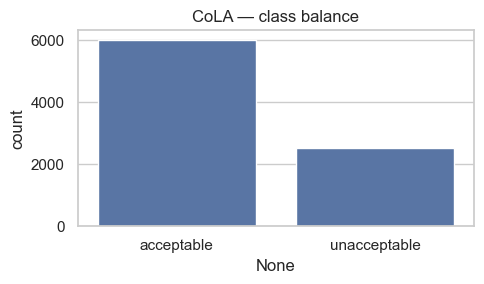

acceptable      0.704
unacceptable    0.296
Name: proportion, dtype: float64


In [66]:
# Class balance - this time it is NOT balanced!
cola_labels = pd.Series(raw_cola["train"]["label"]).map({0: "unacceptable", 1: "acceptable"})

plt.figure(figsize=(5, 3))
sns.countplot(x=cola_labels)
plt.title("CoLA — class balance")
plt.tight_layout(); plt.show()

print(cola_labels.value_counts(normalize=True).round(3))

## ⚠️ Why accuracy is a trap here

About **70 %** of the sentences are acceptable. So a "model" that ignores the input and
always answers *acceptable* scores **70 % accuracy** — while being completely useless.

The official CoLA metric is therefore the **Matthews correlation coefficient (MCC)**:

$$\text{MCC} = \frac{TP \cdot TN - FP \cdot FN}{\sqrt{(TP+FP)(TP+FN)(TN+FP)(TN+FN)}}$$

| MCC | Meaning |
|---|---|
| $+1$ | perfect prediction |
| $0$ | no better than random guessing |
| $-1$ | perfectly wrong |

MCC uses **all four cells** of the confusion matrix, so it cannot be fooled by a
majority-class predictor. Let's verify that claim with actual numbers.

In [67]:
y_val_cola = np.array(raw_cola["validation"]["label"])

# The "dumb" baseline: always predict class 1 (acceptable)
dumb = np.ones_like(y_val_cola)

print(f"Majority baseline accuracy: {accuracy_score(y_val_cola, dumb):.3f}   <- looks fine!")
print(f"Majority baseline MCC     : {matthews_corrcoef(y_val_cola, dumb):.3f}   <- the truth")

Majority baseline accuracy: 0.691   <- looks fine!
Majority baseline MCC     : 0.000   <- the truth


> 🎯 Same predictions, two very different stories. **Choosing the metric is part of
> designing the experiment**, not an afterthought.

## 🚀 Training — exactly the same code

Notice how little has to change: a different dataset, a different column name.
The tokenizer, the loop, the evaluation — all reused.

In [68]:
cola_train_raw = raw_cola["train"].shuffle(seed=SEED).select(range(N_TRAIN))
cola_eval_raw  = raw_cola["validation"]

cola_train = encode(cola_train_raw, "sentence")   # CoLA also uses the column "sentence"
cola_eval  = encode(cola_eval_raw,  "sentence")

cola_train_loader = DataLoader(cola_train, batch_size=BATCH_SIZE, shuffle=True,  collate_fn=collator)
cola_eval_loader  = DataLoader(cola_eval,  batch_size=BATCH_SIZE, shuffle=False, collate_fn=collator)

len(cola_train), len(cola_eval)

Map: 100%|██████████| 1043/1043 [00:00<00:00, 3672.69 examples/s]


(4000, 1043)

In [69]:
# A fresh model - we must NOT continue training the sentiment one!
model_cola = AutoModelForSequenceClassification.from_pretrained(
    CHECKPOINT,
    num_labels=2,
    id2label={0: "unacceptable", 1: "acceptable"},
    label2id={"unacceptable": 0, "acceptable": 1},
).to(device)

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 5262.94it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [70]:
%%time
history_cola = train_model(model_cola, cola_train_loader, cola_eval_loader, epochs=3, lr=2e-5)

epoch 1/3: 100%|██████████| 125/125 [00:02<00:00, 46.08it/s]


  -> epoch 1: validation loss = 0.5243


epoch 2/3: 100%|██████████| 125/125 [00:02<00:00, 50.59it/s]


  -> epoch 2: validation loss = 0.5113


epoch 3/3: 100%|██████████| 125/125 [00:02<00:00, 48.06it/s]


  -> epoch 3: validation loss = 0.5460
CPU times: total: 7.67 s
Wall time: 8.34 s


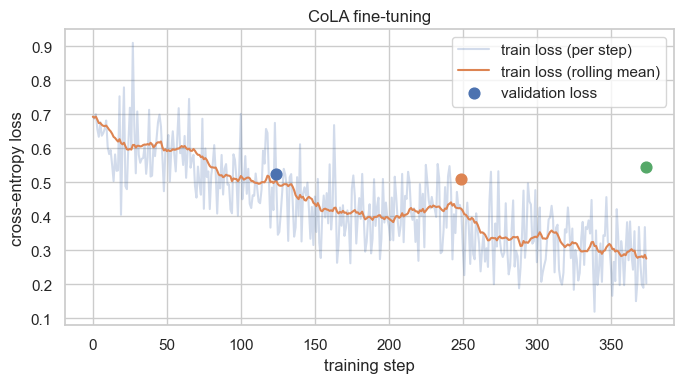

In [71]:
plt.figure(figsize=(7, 4))
plt.plot(history_cola["step_loss"], alpha=0.25, label="train loss (per step)")
plt.plot(pd.Series(history_cola["step_loss"]).rolling(20, min_periods=1).mean(),
         label="train loss (rolling mean)")

steps_per_epoch = len(cola_train_loader)
for i, vl in enumerate(history_cola["val_loss"]):
    plt.scatter((i + 1) * steps_per_epoch - 1, vl, marker="o", s=60, zorder=5,
                label="validation loss" if i == 0 else None)

plt.xlabel("training step")
plt.ylabel("cross-entropy loss")
plt.title("CoLA fine-tuning")
plt.legend()
plt.tight_layout()
plt.show()

In [72]:
logits, y_true = predict(model_cola, cola_eval_loader)
y_pred = logits.argmax(axis=1)

print(f"Accuracy : {accuracy_score(y_true, y_pred):.3f}  (majority baseline: {accuracy_score(y_true, np.ones_like(y_true)):.3f})")
print(f"MCC      : {matthews_corrcoef(y_true, y_pred):.3f}  (majority baseline: 0.000)")
print()
print(classification_report(y_true, y_pred, target_names=["unacceptable", "acceptable"]))

Accuracy : 0.777  (majority baseline: 0.691)
MCC      : 0.440  (majority baseline: 0.000)

              precision    recall  f1-score   support

unacceptable       0.70      0.48      0.57       322
  acceptable       0.80      0.91      0.85       721

    accuracy                           0.78      1043
   macro avg       0.75      0.69      0.71      1043
weighted avg       0.77      0.78      0.76      1043



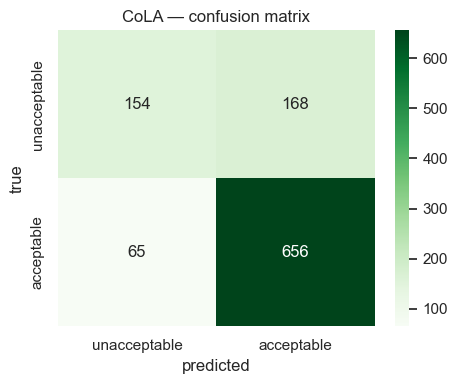

In [73]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(4.8, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens",
            xticklabels=["unacceptable", "acceptable"],
            yticklabels=["unacceptable", "acceptable"])
plt.xlabel("predicted"); plt.ylabel("true")
plt.title("CoLA — confusion matrix")
plt.tight_layout(); plt.show()

> 💡 An MCC around **0.4–0.5** may look modest next to 88 % accuracy on SST-2, but it is
> in the right ballpark for DistilBERT on a small subset (the full-data reference is
> ~0.51). Grammar is simply a harder problem than sentiment. And remember: **0.0 is what
> guessing gets you.**

## 🔮 Does it really understand grammar?

The two sentences below differ by a single misplaced word.

In [74]:
grammar_tests = [
    "The judge told the jurors to think carefully.",        # correct
    "The judge told that the jurors to think carefully.",   # broken
    "The cat sat on the mat.",                              # correct
    "Cat the on mat sat the.",                              # word salad
    "Who did you say that likes the book?",                 # subtly wrong
]

classify(model_cola, grammar_tests)

,sentence,prediction,confidence
0,The judge told the jurors to think carefully.,acceptable,0.964
1,The judge told that the jurors to think carefu...,unacceptable,0.831
2,The cat sat on the mat.,acceptable,0.967
3,Cat the on mat sat the.,unacceptable,0.840
4,Who did you say that likes the book?,acceptable,0.685


# 🎁 Part 7 — Two shortcuts worth knowing

## 💾 Saving and loading your model

`save_pretrained` writes the weights, the config **and** the tokenizer, so the model can
later be loaded with one line — or shared on the Hugging Face Hub.

In [75]:
model_sst2.save_pretrained("./my_sentiment_model")
tokenizer.save_pretrained("./my_sentiment_model")

# Loading it back later:
# reloaded = AutoModelForSequenceClassification.from_pretrained("./my_sentiment_model")

!ls -lh ./my_sentiment_model

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  5.43it/s]
'ls' is not recognized as an internal or external command,
operable program or batch file.


In [76]:
# Our own fine-tuned model can be wrapped in a pipeline, just like the one from Part 1
my_pipeline = pipeline(
    "text-classification",
    model=model_sst2,
    tokenizer=tokenizer,
    device=0 if torch.cuda.is_available() else -1,
)

my_pipeline(["What a wonderful evening.", "Total waste of money."])

[{'label': 'positive', 'score': 0.9776176810264587},
 {'label': 'negative', 'score': 0.9616102576255798}]

# Activities ✏️

Activity 1 is above (fooling the pipeline).
Here are the rest — each cell is pre-filled, you only replace the `TODO` parts.

## ✏️ Activity 2 — Freeze the backbone 🧊

So far we updated **all 66 million parameters**. An alternative is to **freeze the
transformer** and train **only the classification head** — the backbone then works as a
fixed feature extractor.

In PyTorch this is a single attribute: `param.requires_grad = False`.

**Your task:**

1. Run the cell below and note the number of *trainable* parameters.
2. Train it and compare with the fully fine-tuned model in terms of
   **training time** and **accuracy**.
3. Explain the result: why is it faster, and why is it worse?

> 💡 Expect roughly 80 % accuracy instead of 88 %, in a fraction of the time.
> Frozen features are a good choice when you have very little data or no GPU.

In [ ]:
model_frozen = AutoModelForSequenceClassification.from_pretrained(
    CHECKPOINT, num_labels=2, id2label=id2label, label2id=label2id
).to(device)

# Freeze the whole transformer body (everything except the classification head)
for param in model_frozen.distilbert.parameters():
    param.requires_grad = False

trainable = sum(p.numel() for p in model_frozen.parameters() if p.requires_grad)
total     = sum(p.numel() for p in model_frozen.parameters())
print(f"trainable parameters: {trainable:,} / {total:,}  ({100 * trainable / total:.2f} %)")

## ✏️ Activity 3 — Swap the model 🔄

Everything in this notebook is driven by one string: `CHECKPOINT`. Changing it changes
the model **and** its tokenizer, and nothing else in the code has to move.

**Your task:** pick a different checkpoint, re-run the SST-2 fine-tuning and compare.

| Checkpoint | Size | Note |
|---|---|---|
| `distilbert-base-uncased` | 66 M | our baseline |
| `bert-base-uncased` | 110 M | the original BERT — slower, usually a bit better |
| `roberta-base` | 125 M | better pre-training recipe |
| `google/bert_uncased_L-2_H-128_A-2` | 4 M | *tiny* BERT — very fast, much weaker |

**Questions to answer:** Does a bigger model win? Is the gain worth the extra time?
How does the tokenizer output change (compare `tokenizer.tokenize` on the same sentence)?

> ⚠️ If you switch to `roberta-base`, remember that its freezing attribute is
> `model.roberta`, not `model.distilbert`.

## ✏️ Activity 4 — How much data do you actually need? 📉

Transfer learning is famously data-efficient. Let's measure how much.

**Your task:** fine-tune SST-2 with `N_TRAIN` = **500**, **2000** and **8000** examples
(1 epoch each, fresh model every time) and plot **accuracy vs. training-set size**.

**Question:** where does the curve start to flatten out? What would that mean if
labelling one example cost you 10 CZK?

## ✏️ Activity 5 — the Pipelines API on IMDB 🎬

The [Pipelines API](https://huggingface.co/docs/transformers/en/main_classes/pipelines)
is the fastest way to use *any* model from the
[Hugging Face model collection](https://huggingface.co/models).

**Your task:**

1. Load the **IMDB** dataset (`load_dataset("imdb")`) — full movie reviews, much longer
   than SST-2 sentences.
2. Take a random sample of **1 000 test reviews**.
3. Classify them with a `pipeline` (you may use
   `distilbert-base-uncased-finetuned-sst-2-english`, or fine-tune your own model).
4. Report **accuracy** and a **confusion matrix**.
5. Print **three reviews the model got wrong** and write one sentence about *why* you
   think it failed.

> ⚠️ IMDB reviews are often longer than 512 tokens — pass `truncation=True` to the
> pipeline, and think about what information you lose by cutting the text.

In [81]:
imdb = load_dataset("stanfordnlp/imdb")
imdb

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})